# 01 · Triage: the rule engine that decides who gets an LLM

**You'll learn:** what a transaction looks like, which signals triage scores, how the thresholds route each transaction, how account memory raises the score, and how much traffic actually reaches the expensive AI agents.

**Time:** about 10 minutes · **Cost:** free · **Needs:** no API key; triage uses no LLM.

![diagram](attachment:2f32495ee959.png)

| Part | What it covers | Code |
|---|---|---|
| 1 | Setup | |
| 2 | The transactions | `data/synthetic_transactions.py` |
| 3 | The data triage looks up | `tools/mock_apis.py` |
| 4 | The scoring rules, signal by signal | `nodes/triage.py` |
| 5 | Routing | `nodes/triage.py: route_after_triage()` |
| 6 | Account memory raises the score | `nodes/triage.py: _account_memory_penalty()` |
| 7 | How much traffic reaches the LLM? | |
| 8 | Recap and things to try | |

---
## Part 1 · Setup

### Setup
The next cell connects the notebook to the project. It gives this notebook **its own** database files in `.notebook_state/`, so nothing here touches the Streamlit app's data. It prints which LLM this run uses and whether its key is set (never the key itself). Set `SHOW_LIVE_LOGS = True` to see each node's live log line.

In [ ]:
# ── Settings ────────────────────────────────────────────────────────────
# In Colab these show as a checkbox and dropdowns (the model dropdown also takes typed names).
SHOW_LIVE_LOGS = False  # @param {type: "boolean"}
LLM_PROVIDER = "default"  # @param ["default", "gemini", "openai"]
LLM_MODEL = "default"  # @param ["default", "gemini-3.5-flash", "gemini-3.8-flash", "gpt-4o-mini"] {allow-input: true}
# SHOW_LIVE_LOGS: print every node's live log line, like the terminal does.
# LLM_PROVIDER: "default" = .env, else gemini. Needs GEMINI_API_KEY or OPENAI_API_KEY
#   (in Colab: add it under the key icon, Secrets).
# LLM_MODEL: "default" = .env, else the provider's default (gemini-3.5-flash / gpt-4o-mini).
#   Gemini busy (503) or out of free quota (429)? Try gemini-3.8-flash.
# After changing these: Runtime > Restart session > Run all.

# Setup: run from the repo root, and give this notebook its own database files in
# .notebook_state/ so it never touches the app's checkpoints.sqlite / account_memory.sqlite.
import logging
import os
import sys
import warnings
from pathlib import Path

if "google.colab" in sys.modules:
    # Google Colab: the notebook needs the whole repo (it imports core/, agents/, tools/),
    # so clone it and install the pinned packages on first run; later runs pull updates.
    import subprocess

    REPO = Path("/content/fintech-agent")
    if not REPO.exists():
        print("Colab: cloning the repo and installing packages (about a minute)...")
        subprocess.run(["git", "clone", "-q", "-b", "develop-gemini",
                        "https://github.com/iam-suraj-kumar/fintech-agent.git", str(REPO)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO / "requirements.txt")], check=True)
        print("Done. If a later cell fails to import, use Runtime > Restart session and run this cell again.")
    else:
        # Already cloned in this Colab session: pick up any fixes pushed since.
        # (Code already imported stays old until Runtime > Restart session.)
        pulled = subprocess.run(["git", "-C", str(REPO), "pull", "-q", "--ff-only"], capture_output=True, text=True)
        if pulled.returncode != 0:
            print("Colab: could not update the repo:", pulled.stderr.strip())
    os.chdir(REPO)
    from google.colab import userdata  # keys live under the key icon (Secrets) in the sidebar

    for secret in ("GEMINI_API_KEY", "OPENAI_API_KEY"):
        try:
            os.environ.setdefault(secret, userdata.get(secret))
        except Exception:
            pass  # not added (or notebook access is off): fine unless that provider is chosen

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
STATE_DIR = ROOT / ".notebook_state"
STATE_DIR.mkdir(exist_ok=True)
os.environ["CHECKPOINT_DB_PATH"] = str(STATE_DIR / "01_checkpoints.sqlite")
os.environ["MEMORY_DB_PATH"] = str(STATE_DIR / "01_memory.sqlite")
os.environ.setdefault("FASTMCP_LOG_LEVEL", "WARNING")  # quiet the MCP server subprocess
warnings.filterwarnings("ignore")

from dotenv import load_dotenv

load_dotenv(ROOT / ".env")  # never overrides the two database paths set above
# The settings above win over .env unless left at "default".
if LLM_PROVIDER != "default":
    os.environ["LLM_PROVIDER"] = LLM_PROVIDER
if LLM_MODEL != "default":
    os.environ["LLM_MODEL"] = LLM_MODEL
elif LLM_PROVIDER != "default":
    os.environ.pop("LLM_MODEL", None)  # a .env model may belong to the other provider

import pandas as pd

pd.set_option("display.max_colwidth", None)  # show agent findings in full, not cut off with "..."


def trace_table(audit_log: list[dict]) -> pd.DataFrame:
    """One readable line per audit entry (entries have different fields, so a raw table is mostly blanks)."""
    def detail(e: dict) -> str:
        if e["kind"] == "tool_call":
            return f"calls {e['tool']}({e['args']})"
        if e["kind"] == "tool_result":
            return f"{e['tool']} returned {e['result']}"
        return str(e.get("text", ""))
    return pd.DataFrame([{"node": e.get("node", ""), "kind": e["kind"], "detail": detail(e)} for e in audit_log])

from html import escape

from langchain_core.runnables.graph import NodeStyles

# Explicit colours so the boxes read on both light and dark themes
# (LangGraph's default fills are pale but leave the text colour to the theme).
GRAPH_STYLES = NodeStyles(
    default="fill:#DCE6FA,stroke:#2459C2,stroke-width:1px,color:#15202E,line-height:1.2",
    first="fill:#2459C2,stroke:#2459C2,color:#FFFFFF",
    last="fill:#2F7A4A,stroke:#2F7A4A,color:#FFFFFF",
)


class _MermaidGraph:
    """Displays Mermaid code as a diagram. JupyterLab and VS Code draw Mermaid themselves;
    Colab doesn't, so there the browser draws it with Mermaid's JavaScript."""

    def __init__(self, source: str):
        self.source = source

    def _repr_mimebundle_(self, include=None, exclude=None):
        html = (
            '<div style="background:#fff;padding:10px;border-radius:6px;display:inline-block">'
            '<pre class="mermaid">' + escape(self.source) + "</pre></div>"
            '<script type="module">'
            'import mermaid from "https://cdn.jsdelivr.net/npm/mermaid@11.4.1/dist/mermaid.esm.min.mjs";'
            'mermaid.initialize({startOnLoad: false, theme: "default"});'
            'await mermaid.run({querySelector: "pre.mermaid:not([data-processed])"});'
            "</script>"
        )
        if "google.colab" in sys.modules:
            return {"text/html": html}
        return {"text/markdown": "```mermaid\n" + self.source + "\n```"}


def show_graph(app):
    """Draw a compiled LangGraph graph."""
    return _MermaidGraph(app.get_graph().draw_mermaid(node_colors=GRAPH_STYLES))

import core.audit  # noqa: F401  (creates the "fraud_guard" live logger)
from core.llm import llm_model, llm_provider

logging.getLogger("fraud_guard").setLevel(logging.INFO if SHOW_LIVE_LOGS else logging.WARNING)
key = {"gemini": "GEMINI_API_KEY", "openai": "OPENAI_API_KEY"}.get(llm_provider(), "?")
print(f"LLM: {llm_provider()} / {llm_model()}   ({key} set: {'yes' if os.environ.get(key) else 'NO'})")
if llm_model().startswith("gemini") != (llm_provider() == "gemini"):
    print(f"  ! model {llm_model()!r} doesn't look like a model for {llm_provider()}: check LLM_MODEL above")

LLM: gemini / gemini-3.5-flash   (GEMINI_API_KEY set: yes)


---
## Part 2 · The transactions

Four hand-made scenarios drive the demo. Each is a plain dictionary: who paid (`account_id`), how much, to which merchant, from which device and IP, and for wires, to which beneficiary. `ip` is a key into the mock geolocation table; `real_ip` is a genuine public IP for the live MCP lookup in notebook 02.

In [ ]:
from data.synthetic_transactions import SCENARIOS, get_scenario

pd.DataFrame(SCENARIOS).T[["transaction_id", "account_id", "amount", "merchant_id", "device_id", "ip", "type", "beneficiary_name"]].fillna("")  # only wires have a beneficiary

,transaction_id,account_id,amount,merchant_id,device_id,ip,type,beneficiary_name
clean_coffee,txn_001,acct_3003,6.5,merch_coffee_1,dev_known_1,ip_us_ny,card_present,
impossible_travel,txn_002,acct_1001,340.0,merch_electronics_1,dev_new_1,ip_ng_lagos,card_not_present,
borderline_wire,txn_003,acct_2002,18000.0,merch_wire_intl_1,dev_known_1,ip_us_sf,wire_transfer,Global Trading Partners LLC
borderline_restart_demo,txn_004,acct_2002,9500.0,merch_wire_intl_1,dev_new_1,ip_us_sf,wire_transfer,Silk Road Holdings Ltd


Any other ID also works: `get_scenario()` hashes it into a seeded random generator, so the same ID always produces the same plausible transaction (about 1 in 7 lean risky). That is how an audience member can shout out any ID during a demo.

In [ ]:
own = get_scenario("audience-question-42")
assert own == get_scenario("audience-question-42")  # same ID -> same transaction, every time
own

{'transaction_id': 'audience-question-42',
 'account_id': 'acct_4015',
 'amount': 430.9,
 'merchant_id': 'merch_used_car_dealer',
 'device_id': 'dev_107',
 'ip': 'ip_us_austin',
 'real_ip': '105.112.0.1',
 'timestamp': '2027-01-02T06:09:00+00:00',
 'type': 'card_present',
 'source': 'generated'}

---
## Part 3 · The data triage looks up

Triage enriches each transaction with four lookups. In this demo they are mock tables (a real system would call internal services):

In [ ]:
from tools.mock_apis import ACCOUNT_HISTORY, DEVICE_FINGERPRINTS, GEOLOCATIONS, MERCHANT_RISK

accounts = {t["account_id"] for t in SCENARIOS.values()}
display(pd.DataFrame({a: ACCOUNT_HISTORY[a] for a in sorted(accounts)}).T.rename_axis("account"))
display(pd.DataFrame({m: MERCHANT_RISK[m] for m in sorted({t["merchant_id"] for t in SCENARIOS.values()})}).T.rename_axis("merchant"))
display(pd.DataFrame(DEVICE_FINGERPRINTS).T.rename_axis("device"))
pd.DataFrame(GEOLOCATIONS).T.rename_axis("ip key")

,typical_range,country,avg_txn_count_per_week
account,,,
acct_1001,"(5, 150)",US,12
acct_2002,"(500, 5000)",US,3
acct_3003,"(10, 80)",US,20


,tier,score
merchant,,
merch_coffee_1,low,0.05
merch_electronics_1,medium,0.35
merch_wire_intl_1,high,0.72


,known,first_seen_days_ago
device,,
dev_known_1,True,412
dev_new_1,False,0
dev_101,True,620
dev_102,True,45
dev_103,False,0
dev_104,True,210
dev_105,False,0
dev_106,True,900
dev_107,True,15


,country,city
ip key,,
ip_us_ny,US,New York
ip_ng_lagos,NG,Lagos
ip_us_sf,US,San Francisco
ip_us_chicago,US,Chicago
ip_us_austin,US,Austin
ip_us_miami,US,Miami
ip_us_seattle,US,Seattle
ip_uk_london,GB,London
ip_ca_toronto,CA,Toronto


---
## Part 4 · The scoring rules, signal by signal

`_compute_triage_score()` adds up points for each warning sign and caps the total at 1.0. This is the real code:

In [ ]:
import inspect

from nodes.triage import AUTO_DECLINE_THRESHOLD, INVESTIGATE_THRESHOLD, _compute_triage_score

print(inspect.getsource(_compute_triage_score))

def _compute_triage_score(transaction: dict) -> float:
    score = 0.0

    account = get_account_history(transaction["account_id"])
    _, high = account["typical_range"]
    if transaction["amount"] > high * 3:
        score += 0.35
    elif transaction["amount"] > high:
        score += 0.15

    device = get_device_fingerprint(transaction["device_id"])
    if not device["known"]:
        score += 0.15

    merchant = get_merchant_risk_score(transaction["merchant_id"])
    score += merchant["score"] * 0.2

    if transaction.get("beneficiary_is_new"):
        score += 0.15

    prior_ip = transaction.get("prior_ip")
    if prior_ip and prior_ip != transaction["ip"]:
        prior_country = get_geolocation(prior_ip)["country"]
        current_country = get_geolocation(transaction["ip"])["country"]
        if prior_country != current_country:
            score += 0.55

    score += _account_memory_penalty(transaction["account_id"])

    return min(score, 1.0)



The same rules as a table, one column per signal. The helper below restates the code above so each signal's points are visible; the `assert` checks that its total equals the real function's score, so the table can't drift from the code.

In [ ]:
from tools.mock_apis import get_account_history, get_device_fingerprint, get_geolocation, get_merchant_risk_score


def breakdown(t: dict) -> dict:
    high = get_account_history(t["account_id"])["typical_range"][1]
    amount = 0.35 if t["amount"] > high * 3 else 0.15 if t["amount"] > high else 0.0
    device = 0.0 if get_device_fingerprint(t["device_id"])["known"] else 0.15
    merchant = get_merchant_risk_score(t["merchant_id"])["score"] * 0.2
    beneficiary = 0.15 if t.get("beneficiary_is_new") else 0.0
    travel = 0.0
    if t.get("prior_ip") and t["prior_ip"] != t["ip"]:
        if get_geolocation(t["prior_ip"])["country"] != get_geolocation(t["ip"])["country"]:
            travel = 0.55
    total = min(amount + device + merchant + beneficiary + travel, 1.0)
    assert abs(total - _compute_triage_score(t)) < 1e-9  # outside a graph the memory penalty is 0
    return {"unusual amount": amount, "unknown device": device, "merchant risk": round(merchant, 3),
            "new beneficiary": beneficiary, "impossible travel": travel, "SCORE": round(total, 3)}


scores = pd.DataFrame({name: breakdown(t) for name, t in SCENARIOS.items()}).T
scores

,unusual amount,unknown device,merchant risk,new beneficiary,impossible travel,SCORE
clean_coffee,0.00,0.00,0.010,0.00,0.00,0.010
impossible_travel,0.15,0.15,0.070,0.00,0.55,0.920
borderline_wire,0.35,0.00,0.144,0.15,0.00,0.644
borderline_restart_demo,0.15,0.15,0.144,0.15,0.00,0.594


**What to notice:** no single signal decides. The $18,000 wire is unusual (3.6× the account's maximum), to a high-risk merchant and a new beneficiary, but from a known device, so it lands in the middle. Impossible travel alone (US to Nigeria in 10 minutes) adds 0.55.

The chart places each scenario between the two thresholds:

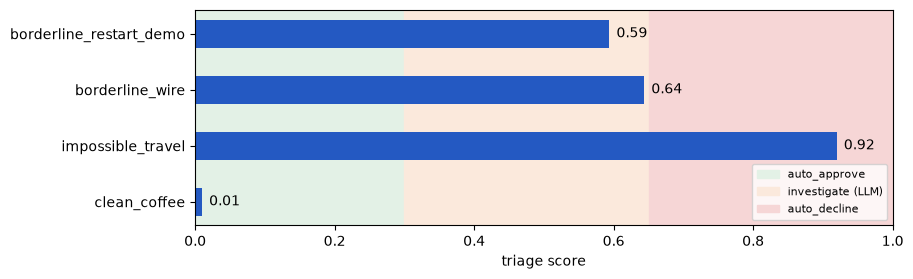

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.axvspan(0, INVESTIGATE_THRESHOLD, color="#E3F1E6", label="auto_approve")
ax.axvspan(INVESTIGATE_THRESHOLD, AUTO_DECLINE_THRESHOLD, color="#FBE9DC", label="investigate (LLM)")
ax.axvspan(AUTO_DECLINE_THRESHOLD, 1.0, color="#F6D6D6", label="auto_decline")
ax.barh(scores.index, scores["SCORE"], color="#2459C2", height=0.5)
for i, value in enumerate(scores["SCORE"]):
    ax.text(value + 0.01, i, f"{value:.2f}", va="center")
ax.set_xlim(0, 1.0)
ax.set_xlabel("triage score")
ax.legend(loc="lower right", fontsize=8)
plt.show()

---
## Part 5 · Routing

`triage_node()` turns the score into a decision; `route_after_triage()` turns the decision into the next node or nodes. For `investigate` it returns **three** node names, which is LangGraph's fan-out: all three specialists start in parallel.

In [ ]:
from core.state import new_state
from nodes.triage import route_after_triage, triage_node

rows = []
for name, t in SCENARIOS.items():
    update = triage_node(new_state(t))
    rows.append({"scenario": name, "score": round(update["triage_score"], 3),
                 "decision": update["triage_decision"], "next nodes": route_after_triage(update)})
pd.DataFrame(rows)

,scenario,score,decision,next nodes
0,clean_coffee,0.010,auto_approve,[auto_approve]
1,impossible_travel,0.920,auto_decline,[auto_decline]
2,borderline_wire,0.644,investigate,"[transaction_analyst, identity_verifier, pattern_detector]"
3,borderline_restart_demo,0.594,investigate,"[transaction_analyst, identity_verifier, pattern_detector]"


---
## Part 6 · Account memory raises the score

After every decision, the `resolution` node writes it to the long-term store under `("account_memory", account_id)`. Triage reads it back: **+0.15 per past escalation, +0.10 per past decline, at most +0.30.**

`get_store()` only works inside a graph, so this cell wraps the real `triage_node` in a one-node graph with an in-memory store, scores `borderline_restart_demo`, then adds two past escalations for the same account and scores it again.

In [ ]:
from langgraph.graph import END, START, StateGraph
from langgraph.store.memory import InMemoryStore

from core.state import TransactionState


def triage_with(store):
    builder = StateGraph(TransactionState)
    builder.add_node("triage", triage_node)
    builder.add_edge(START, "triage")
    builder.add_edge("triage", END)
    return builder.compile(store=store)


txn = SCENARIOS["borderline_restart_demo"]
store = InMemoryStore()
before = triage_with(store).invoke(new_state(txn))
for i in range(2):
    store.put(("account_memory", txn["account_id"]), f"past-{i}", {"final_decision": "escalated"})
after = triage_with(store).invoke(new_state(txn))

pd.DataFrame([
    {"account history": "clean", "score": round(before["triage_score"], 3), "decision": before["triage_decision"]},
    {"account history": "2 past escalations", "score": round(after["triage_score"], 3), "decision": after["triage_decision"]},
])

,account history,score,decision
0,clean,0.594,investigate
1,2 past escalations,0.894,auto_decline


**What to notice:** the same transaction moves from *investigate* to *auto_decline* because the account has a track record. This is also why the app wipes memory on start by default (`RESET_MEMORY_ON_START=true`): repeated rehearsals on the same demo account would otherwise auto-decline it.

---
## Part 7 · How much traffic reaches the LLM?

The point of triage is cost. Generating 500 random transactions and triaging them shows the split: only the middle band pays for LLM calls.

,transactions,share
auto_approve,428,86%
investigate,44,9%
auto_decline,28,6%


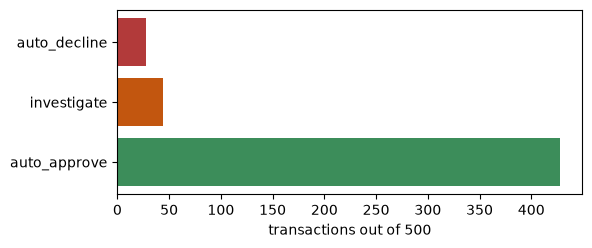

In [ ]:
sample = [get_scenario(f"random-{i}") for i in range(500)]
decisions = pd.Series([triage_node(new_state(t))["triage_decision"] for t in sample]).value_counts()
display(decisions.to_frame("transactions").assign(share=lambda d: (d.transactions / d.transactions.sum()).map("{:.0%}".format)))

fig, ax = plt.subplots(figsize=(6, 2.4))
colors = {"auto_approve": "#3C8D5A", "investigate": "#C2560F", "auto_decline": "#B23A3A"}
ax.barh(decisions.index, decisions.values, color=[colors[d] for d in decisions.index])
ax.set_xlabel("transactions out of 500")
plt.show()

---
## Part 8 · Recap and things to try

**What happened:** each transaction got points for five warning signs plus its account's history; the total routed it to approve, decline, or the three AI specialists. No LLM was called.

**Try this**
- Make a transaction of your own: copy `SCENARIOS["borderline_wire"]`, change the amount to 3,000, and run `breakdown()` on it.
- Move a threshold: what share goes to `investigate` if `INVESTIGATE_THRESHOLD` were 0.20?
- Add a past *decline* instead of an escalation in Part 6. How much does the score move?

**Next:** `02_specialist_agents.ipynb`: the three AI specialists that investigate the middle band.